# Empirical activation similarity (EAS) — student-vs-teacher analysis

Live analysis of the per-student-run EAS documents at `outputs/students/.../eval/eas_{position}.json` (written by `scripts/sweeps/sweep_compute_eas.py` / `pipelines.eas_pipeline`). EAS is the per-layer cosine between a **reference teacher's** activation-shift vector and a student **checkpoint's** shift, measured on that student's own training prompts; `eas_mean` is the mean over the per-layer slots `[1:]` — the embedding slot dropped, every remaining slot a raw block output with the final block included (the **`raw_blocks_v2`** basis; the old `blocks_v1` `[1:-1]` convention and its post-final-LN slot are retired). **EAS is signed**, so every heatmap uses a diverging map centred at 0.

Since the 2026-09-10 migration one document covers ONE student run and holds one record per checkpoint (`step`), scored against one or more reference teachers. Controls (`source` `base`/`rng`) are scored **on their own training prompts against a named reference teacher**, so a control row is identified by `is_own_reference == False` (or `source != 'teacher'`) rather than by being a shared re-scored student.

Run from the repo root with `uv run --group analysis jupyter lab`. Every section guards its selection and prints a *no data yet* notice instead of raising, so reading mid-sweep (or before any new-format document exists) is expected and safe.

## §0 Load + coverage

In [1]:
from __future__ import annotations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import frames
from subliminal_learning.steering.eas_results_io import (
    endpoint_only, load_eas_results, own_reference_only,
)

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style()

# ---- top-level knobs ----
POSITION = 'last'
PRIMARY_ANIMAL = 'dog'
PRIMARY_MODEL = 'pythia-160m'
PRIMARY_TAG = 'ex10-20_prefix_n100k'
PRIMARY_STUDENT_EPOCH = 5

# Fixed source colours — the SAME colour follows each entity in every figure below.
SOURCE_COLORS = {'teacher': 'tab:blue', 'base': 'tab:orange', 'rng': 'tab:gray'}
SOURCE_ORDER = ['teacher', 'base', 'rng']
EAS_LABEL = 'EAS (mean cosine over raw block slots [1:])'

df = load_eas_results(OUTPUT_ROOT)
print(f'{len(df)} EAS rows = (student run x checkpoint x reference teacher) '
      f'across {df.run_path.nunique() if len(df) else 0} student run(s).')


def need(frame, what=''):
    """True when `frame` has rows; otherwise print the standard 'run the sweep' note and False.

    `frames.filter_grid` does not apply here (its axes are the teacher-FT column names), so the
    EAS frame gets this one local guard instead of eight copies of the same message.
    """
    if len(frame):
        return True
    print(f'no EAS data yet{f" for {what}" if what else ""} — run scripts/sweeps/sweep_compute_eas.py')
    return False


def eas_slice(*, source=None, animal=None, model=None, models=None, tag=None, tags=None,
              cross_base=None, epoch=None, teacher_tag=None, teacher_ftseed=None,
              own_reference=None, endpoint=None, position=POSITION):
    """The one boolean-mask slicer for `df`; every stated keyword ANDs one equality/membership.

    `cross_base=False` keeps the same-base runs (§1-§5), `True` the cross-base ones (§6);
    `own_reference=True` keeps only rows scored against the run's OWN reference teacher;
    `endpoint=True` keeps the final checkpoint of each run. ``None`` leaves an axis alone.
    """
    if df.empty:
        return df
    m = df.position == position
    if source is not None:
        m &= df.source == source
    if animal is not None:
        m &= df.animal == animal
    if model is not None:
        m &= df.model == model
    if models is not None:
        m &= df.model.isin(models)
    if tag is not None:
        m &= df.dataset_tag == tag
    if tags is not None:
        m &= df.dataset_tag.isin(tags)
    if cross_base is not None:
        m &= df.cross_base.astype(bool) == bool(cross_base)
    if epoch is not None:
        m &= df.student_epochs == epoch
    if teacher_tag is not None:
        m &= df.teacher_param_tag == teacher_tag
    if teacher_ftseed is not None:
        m &= df.teacher_ftseed == teacher_ftseed
    if own_reference is not None:
        m &= df.is_own_reference.astype(bool) == bool(own_reference)
    if endpoint is not None:
        m &= df.is_endpoint.astype(bool) == bool(endpoint)
    sub = df[m]
    return sub[~sub.nonfinite.astype(bool)] if len(sub) else sub


def is_control(frame):
    """Boolean mask of CONTROL rows: a non-teacher source, or a teacher-source run scored
    against a reference that is not its own."""
    if frame.empty:
        return frame.index == frame.index  # empty mask, right dtype
    return (~frame.is_own_reference.astype(bool)) | (frame.source != 'teacher')

19024 EAS rows = (student run x checkpoint x reference teacher) across 464 student run(s).


In [2]:
# Coverage table. Row unit = one student run x position; aggregation = count of runs and of
# scored checkpoints; selection = every run with a new-format EAS document under OUTPUT_ROOT.
if need(df, 'any student run'):
    runs = df.drop_duplicates(['run_path', 'position'])
    cov = (
        runs.groupby(['animal', 'model', 'dataset_tag', 'source', 'position'])
        .agg(n_runs=('run_path', 'nunique'))
    )
    steps = (
        df.drop_duplicates(['run_path', 'position', 'step'])
        .groupby(['animal', 'model', 'dataset_tag', 'source', 'position']).size()
        .rename('n_checkpoints')
    )
    display(cov.join(steps))
    print('Row unit: (animal, model, dataset tag, source, position). '
          'n_runs = distinct student run dirs; n_checkpoints = distinct (run, step) records. '
          'Reading mid-sweep is expected — counts grow as the sweep runs.')

,,,,,n_runs,n_checkpoints
animal,model,dataset_tag,source,position,,
dog,pythia-160m-data-seed1,ex10-20_prefix_n100k,teacher,last,464,18560


Row unit: (animal, model, dataset tag, source, position). n_runs = distinct student run dirs; n_checkpoints = distinct (run, step) records. Reading mid-sweep is expected — counts grow as the sweep runs.


## §1 EAS vs training step (dose-response)

Each point is one student **checkpoint**: the base-relative activation-shift vectors `v = mean_act(model) − mean_act(base)` compared as a **per-layer cosine** against a reference teacher's shift, then averaged over the raw block slots `[1:]` (`raw_blocks_v2`). The three lines are the student's **training-data source**:

- **teacher** — numbers a fine-tuned teacher produced (the subliminal channel),
- **base** — numbers the untuned base produced (a per-base control),
- **rng** — random-digit numbers (the trait-free floor).

The x-axis is the checkpoint **step** within one run, so the curve is a within-run trajectory; the second figure is the endpoint-only view by **student epochs** (each epoch an INDEPENDENT cosine-schedule run), which reproduces the old cross-run dose view.

Teacher-source rows are **matched pairs** (each student against its own reference teacher, `is_own_reference`); control rows are `base`/`rng` runs distilled on their OWN training prompts and scored against a **named reference teacher** — the null level for that teacher direction. Curves aggregate **mean ± 95% CI across student runs** at student ftseed1.

**Same-base only** — cross-base runs (student base ≠ teacher base) are §6.

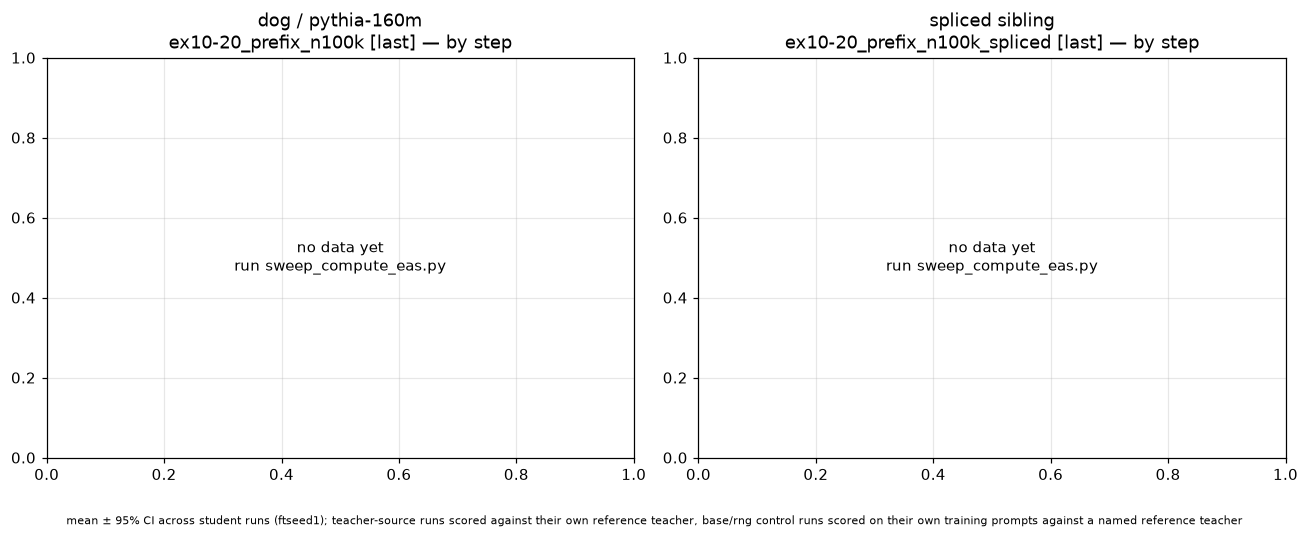

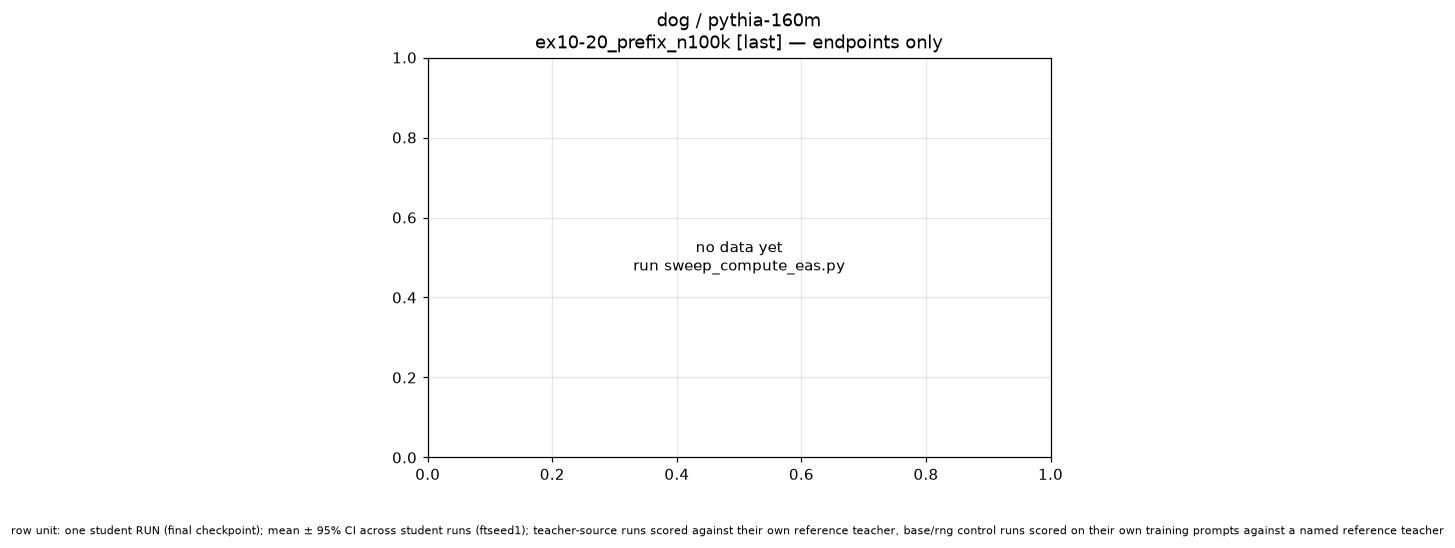

no EAS data yet for same-base prefix tags at position=last — run scripts/sweeps/sweep_compute_eas.py


In [3]:
def primary_df(tag, **kw):
    # Same-base only (cross_base=False); cross-base runs belong to §6.
    return eas_slice(cross_base=False, animal=PRIMARY_ANIMAL, model=PRIMARY_MODEL, tag=tag, **kw)

# Unspliced free-generation prefix tags the per-(animal, model) facets are restricted to.
PREFIX_TAGS = ('ex10-20_prefix_n40k', 'ex10-20_prefix_n100k')

# One-line statement of what the curves aggregate, printed under every §1 figure.
AGG_CAPTION = ('mean ± 95% CI across student runs (ftseed1); teacher-source runs scored against '
               'their own reference teacher, base/rng control runs scored on their own training '
               'prompts against a named reference teacher')

def _run_count(s):
    """Distinct student runs in a source's selection at its first x value present."""
    if s.empty:
        return 0
    return s.drop_duplicates(['run_path', 'reference']).shape[0]

def dose_plot(ax, sub, title, x='step', xlabel='checkpoint step'):
    if sub.empty:
        ax.text(0.5, 0.5, 'no data yet\nrun sweep_compute_eas.py', ha='center', va='center',
                transform=ax.transAxes)
        ax.set_title(title)
        return
    n_series = aplots.dose_response(ax, sub, x=x, y='eas_mean', group='source',
                                    order=SOURCE_ORDER, colors=SOURCE_COLORS,
                                    labels={s: s for s in SOURCE_ORDER}, zero_line=True,
                                    count_fn=_run_count)
    ax.set(xlabel=xlabel, ylabel=EAS_LABEL, title=title)
    if n_series >= 1:
        ax.legend(fontsize=8)

if need(df):
    # Row unit = one (run, checkpoint, reference) row; aggregation = mean ± 95% CI over runs at
    # each step; selection = same-base primary animal/model, one tag per panel.
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
    dose_plot(axs[0], primary_df(PRIMARY_TAG),
              f'{PRIMARY_ANIMAL} / {PRIMARY_MODEL}\n{PRIMARY_TAG} [{POSITION}] — by step')
    dose_plot(axs[1], primary_df(PRIMARY_TAG + '_spliced'),
              f'spliced sibling\n{PRIMARY_TAG}_spliced [{POSITION}] — by step')
    fig.text(0.5, -0.03, AGG_CAPTION, ha='center', va='top', fontsize=7.5)
    plt.tight_layout(); plt.show()

    # Endpoint-only variant: one row per run (final checkpoint), x = student epochs.
    fig, ax = plt.subplots(figsize=(6.4, 4.6))
    dose_plot(ax, primary_df(PRIMARY_TAG, endpoint=True),
              f'{PRIMARY_ANIMAL} / {PRIMARY_MODEL}\n{PRIMARY_TAG} [{POSITION}] — endpoints only',
              x='student_epochs', xlabel='student epochs (independent runs)')
    fig.text(0.5, -0.05, 'row unit: one student RUN (final checkpoint); ' + AGG_CAPTION,
             ha='center', va='top', fontsize=7.5)
    plt.tight_layout(); plt.show()

    # Small multiples: one facet per same-base (animal, model), restricted to the unspliced
    # free-generation prefix tags. NOT pooled across base models, NOT mixing other tags.
    prefix = eas_slice(cross_base=False, tags=PREFIX_TAGS)
    pairs = (sorted(map(tuple, prefix[['animal', 'model']].drop_duplicates().values.tolist()))
             if len(prefix) else [])
    if need(pairs, f'same-base prefix tags at position={POSITION}'):
        fig, axs = plt.subplots(1, len(pairs), figsize=(5 * len(pairs), 4.4), squeeze=False)
        for ax, (an, mdl) in zip(axs[0], pairs):
            sub = prefix[(prefix.animal == an) & (prefix.model == mdl)]
            tags_here = sorted(sub.dataset_tag.unique())
            dose_plot(ax, sub, f'{an} / {mdl}\n{" + ".join(tags_here)} [{POSITION}] — by step')
        fig.text(0.5, -0.03, AGG_CAPTION, ha='center', va='top', fontsize=7.5)
        plt.tight_layout(); plt.show()

## §2 Per-layer profiles

Left: mean per-slot cosine by source at the primary student epoch (endpoint checkpoints). The solid line is the `[1:]` raw-block profile that feeds `eas_mean`; only the excluded slot-0 (embedding) is drawn as a hollow square with a dashed connector, because in the `raw_blocks_v2` basis the final slot IS the final block's raw output and is scored (there is no post-final-LN slot any more). Right: the teacher-source profile per checkpoint step.

In [4]:
def mean_profile(rows):
    """Mean per-slot EAS profile over `rows` (row unit = one (run, checkpoint, reference))."""
    vals = [np.asarray(v, float) for v in rows.eas_per_layer if v is not None]
    return np.vstack(vals).mean(0) if vals else None


def plot_profile(ax, prof, color, label, ends=False):
    """One per-slot EAS curve: solid over the scored slots [1:].

    `ends=True` adds this notebook's excluded-slot convention — slot 0 (the embedding) drawn as a
    dashed stub with an open square marker, so it reads as context, not as scored data."""
    idx = np.arange(len(prof))
    ax.plot(idx[1:], prof[1:], '-o', color=color, label=label)
    if ends:
        ax.plot(idx[:2], prof[:2], '--', color=color, alpha=0.5)
        ax.scatter([idx[0]], [prof[0]], facecolors='none', edgecolors=color, marker='s')

sub = primary_df(PRIMARY_TAG)
at = sub[sub.student_epochs == PRIMARY_STUDENT_EPOCH] if len(sub) else sub
at = at[at.is_endpoint.astype(bool)] if len(at) else at
if need(at, f'{PRIMARY_ANIMAL}/{PRIMARY_MODEL}/{PRIMARY_TAG} ep{PRIMARY_STUDENT_EPOCH} [{POSITION}]'):
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
    ax = axs[0]
    for src in SOURCE_ORDER:
        s = at[at.source == src]
        prof = mean_profile(s) if not s.empty else None
        if prof is None:
            continue
        plot_profile(ax, prof, SOURCE_COLORS[src], f'{src} (n={len(s)})', ends=True)
    ax.axhline(0.0, color='0.7', lw=0.8)
    ax.set(xlabel='hidden-state slot index', ylabel='per-slot EAS (cosine)',
           title=(f'per-slot profile by source — row unit (run, endpoint ckpt, reference),\n'
                  f'mean over runs at ep{PRIMARY_STUDENT_EPOCH}; square = excluded slot 0'))
    ax.legend()

    ax = axs[1]
    ts = sub[sub.source == 'teacher']
    steps = sorted(ts.step.unique()) if len(ts) else []
    if not steps:
        ax.text(0.5, 0.5, 'no teacher-source data yet', ha='center', va='center', transform=ax.transAxes)
        ax.set_title('teacher-source profile per checkpoint step')
    else:
        cols = plt.cm.viridis(np.linspace(0, 1, len(steps)))
        for st, col in zip(steps, cols):
            prof = mean_profile(ts[ts.step == st])
            if prof is not None:
                plot_profile(ax, prof, col, f'step {st}')
        ax.axhline(0.0, color='0.7', lw=0.8)
        ax.set(xlabel='hidden-state slot index', ylabel='per-slot EAS (cosine)',
               title='teacher-source profile per checkpoint step\n(mean over runs at each step)')
        if len(steps) >= 2:
            ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

no EAS data yet for dog/pythia-160m/ex10-20_prefix_n100k ep5 [last] — run scripts/sweeps/sweep_compute_eas.py


## §3 Cross-model / cross-animal comparison

(a) `cat` across its base models (the original plus the 6 data/weight-seed models) at matched teacher HPs — teacher-source `eas_mean` at the primary student epoch, endpoint checkpoints, own reference only. (b) `dog` vs `cat` on the models they share.

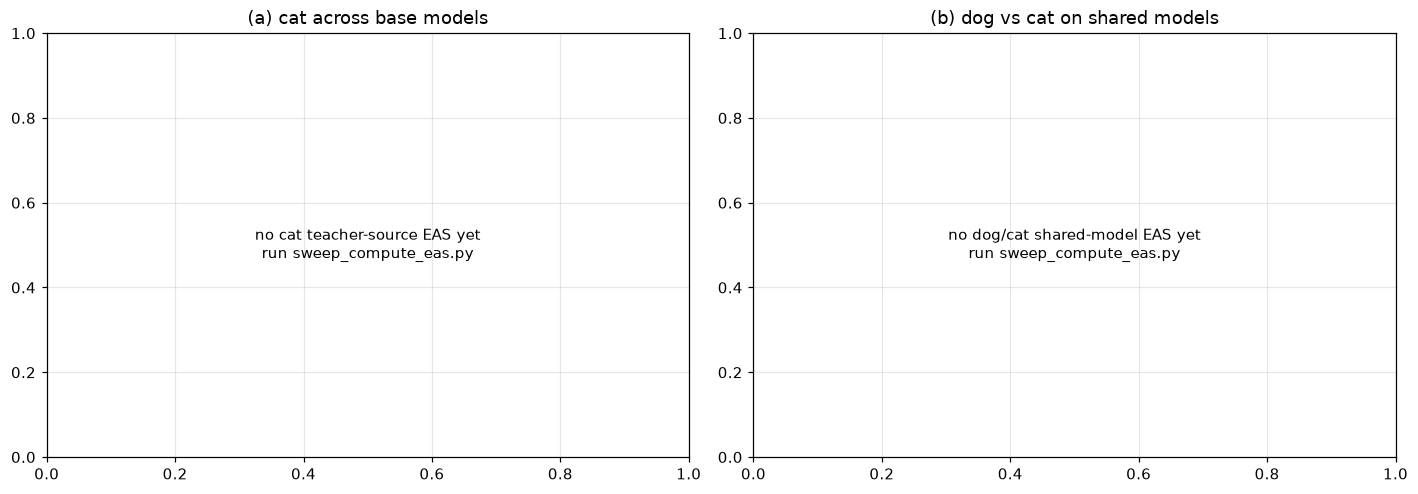

In [5]:
def teacher_slice(animal, epoch=PRIMARY_STUDENT_EPOCH, tag=None):
    # Own-reference, endpoint rows only: one row per student run.
    return eas_slice(animal=animal, source='teacher', epoch=epoch, tag=tag,
                     own_reference=True, endpoint=True)

if need(df):
    # Row unit = one student run (endpoint ckpt vs own reference teacher); no averaging inside
    # the strips — every run is a point; selection = teacher-source, ep{PRIMARY_STUDENT_EPOCH}.
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
    # (a) cat across its base models.
    cat = teacher_slice('cat')
    if cat.empty:
        axs[0].text(0.5, 0.5, 'no cat teacher-source EAS yet\nrun sweep_compute_eas.py',
                    ha='center', va='center', transform=axs[0].transAxes)
        axs[0].set_title('(a) cat across base models')
    else:
        models = sorted(cat.model.unique())
        groups = [cat[cat.model == mdl].eas_mean.values for mdl in models]
        aplots.strip_box(axs[0], groups, models, colors=['tab:blue'] * len(models), zero_line=True)
        axs[0].set(ylabel=f'teacher-source EAS (ep{PRIMARY_STUDENT_EPOCH} endpoints)',
                   title='(a) cat across base models (matched teacher HPs; one point = one run)')
    # (b) dog vs cat on shared models.
    dog = teacher_slice('dog')
    catt = teacher_slice('cat')
    shared = (sorted(set(dog.model.unique()) & set(catt.model.unique()))
              if len(dog) and len(catt) else [])
    if not shared:
        axs[1].text(0.5, 0.5, 'no dog/cat shared-model EAS yet\nrun sweep_compute_eas.py',
                    ha='center', va='center', transform=axs[1].transAxes)
        axs[1].set_title('(b) dog vs cat on shared models')
    else:
        labels, groups, colors = [], [], []
        for mdl in shared:
            labels += [f'dog\n{mdl}', f'cat\n{mdl}']
            groups += [dog[dog.model == mdl].eas_mean.values, catt[catt.model == mdl].eas_mean.values]
            colors += ['tab:blue', 'tab:green']
        aplots.strip_box(axs[1], groups, labels, colors=colors, zero_line=True)
        axs[1].set(ylabel=f'teacher-source EAS (ep{PRIMARY_STUDENT_EPOCH} endpoints)',
                   title='(b) dog vs cat on shared models (one point = one run)')
    plt.tight_layout(); plt.show()

## §4 Zoomed-out 2D teacher-HP tables

Rows = teacher LoRA `r{r}a{a}` (sorted by r then alpha), cols = teacher epochs, one subplot per teacher lr — the HPs of the **reference teacher** each run was scored against. Cells are teacher-source `eas_mean` at the primary student epoch (endpoint checkpoints, mean over student seeds); the second call swaps in the student-dose delta (ep10 − ep1). Diverging `RdBu_r` centred at 0 with a shared colour scale across the whole figure; cells annotated.

In [6]:
def hp_table(animal, model, tag, metric='eas', position=POSITION, epoch=PRIMARY_STUDENT_EPOCH):
    sub = eas_slice(position=position, animal=animal, model=model, tag=tag, source='teacher',
                    own_reference=True, endpoint=True)
    if sub.empty:
        need(sub, f'teacher-source {animal}/{model}/{tag} [{position}]')
        return
    keys = ['teacher_lr', 'teacher_lora_r', 'teacher_lora_alpha', 'teacher_epochs']
    if metric == 'eas':
        g = sub[sub.student_epochs == epoch].groupby(keys).eas_mean.mean().rename('val').reset_index()
        mlabel = f'teacher-source EAS (student ep{epoch} endpoints, mean over student seeds)'
    elif metric == 'dose_delta':
        p = sub.groupby(keys + ['student_epochs']).eas_mean.mean().reset_index()
        w = p.pivot_table(index=keys, columns='student_epochs', values='eas_mean')
        if 1 not in w.columns or 10 not in w.columns:
            print('need student ep1 and ep10 for the dose delta — not available yet')
            return
        g = (w[10] - w[1]).rename('val').reset_index()
        mlabel = 'student-dose \u0394EAS (ep10 \u2212 ep1)'
    else:
        raise ValueError(metric)
    g = g.dropna(subset=['val'])
    if g.empty:
        print(f'no populated cells for {animal}/{model}/{tag} [{position}] metric={metric}')
        return
    # Tidy long frame for the faceted grid: ordered r/alpha row axis, teacher epochs, teacher_lr, val.
    ras = sorted(set(zip(g.teacher_lora_r, g.teacher_lora_alpha)))  # sort by r then alpha
    ra_cats = [f'r{r}a{a}' for r, a in ras]
    g['teacher LoRA r / alpha'] = [f'r{r}a{a}' for r, a in
                                   zip(g.teacher_lora_r, g.teacher_lora_alpha)]
    g = g.rename(columns={'teacher_epochs': 'teacher epochs'})
    vmax = max(float(np.nanmax(np.abs(g.val))), 1e-9)   # never a degenerate 0-width norm
    norm = TwoSlopeNorm(vcenter=0.0, vmin=-vmax, vmax=vmax)
    _ = aplots.facet_grid_heatmaps(
        g, row='teacher LoRA r / alpha', col='teacher epochs', val='val',
        col_facet='teacher_lr', orders={'teacher LoRA r / alpha': ra_cats},
        norm=norm, cmap='RdBu_r', text_color='black', fmt='{:.2f}', cell_fontsize=8,
        col_facet_label=lambda lr: f'lr={lr:g}',
        title=f'{animal} / {model} · {tag} [{position}] — {mlabel}', cbar_label=mlabel,
    )
    print('Cell unit: one reference-teacher HP config; aggregation: mean over student runs/seeds; '
          'selection: teacher-source own-reference endpoint rows.')
    plt.show()

if need(df):
    hp_table(PRIMARY_ANIMAL, PRIMARY_MODEL, PRIMARY_TAG, 'eas')
    hp_table(PRIMARY_ANIMAL, PRIMARY_MODEL, PRIMARY_TAG, 'dose_delta')

no EAS data yet for teacher-source dog/pythia-160m/ex10-20_prefix_n100k [last] — run scripts/sweeps/sweep_compute_eas.py
no EAS data yet for teacher-source dog/pythia-160m/ex10-20_prefix_n100k [last] — run scripts/sweeps/sweep_compute_eas.py


## §5 EAS vs behavioral transfer

Join each teacher-source student run's endpoint EAS to its own `preference_summary.json` (`test` p(target) if present, else `validation`) and scatter EAS vs student p(target), one panel per student epoch, annotated with Pearson/Spearman r. The summary lives in the run dir's PARENT `{student_tag}` cell dir, reached from the row's `run_path`. Tolerant to missing summaries.

In [7]:
def load_ptargets(rows):
    """Seed-averaged p(target) per EAS row -- `test` block, else `validation`, else NaN.

    The cell's `preference_summary.json` sits in the run dir's parent `{student_tag}` dir, so the
    join key is the row's `run_path` (no path arithmetic on the document file). Reads go through
    one cached sweep rather than one open per row.
    """
    rels = [str(Path(rp).parent) for rp in rows.run_path]
    docs = frames.load_cell_summaries(OUTPUT_ROOT, sorted(set(rels)))
    out = []
    for rel in rels:
        doc = docs.get(rel)
        block = frames.summary_set_block(doc, 'test') or frames.summary_set_block(doc, 'validation')
        out.append(np.nan if block is None else block.get('p_target_mean'))
    return out

sub = primary_df(PRIMARY_TAG, source='teacher', own_reference=True, endpoint=True).copy()
if need(sub, f'teacher-source {PRIMARY_ANIMAL}/{PRIMARY_MODEL}/{PRIMARY_TAG} [{POSITION}]'):
    sub['p_target'] = load_ptargets(sub)
    sub = sub.dropna(subset=['p_target'])
    if sub.empty:
        print('no preference_summary.json alongside these EAS runs yet — run the student eval sweep')
    else:
        eps = sorted(sub.student_epochs.unique())
        fig, axs = plt.subplots(1, len(eps), figsize=(4.3 * len(eps), 4.2), squeeze=False)
        for ax, ep in zip(axs[0], eps):
            s = sub[sub.student_epochs == ep]
            aplots.identity_scatter(ax, s, 'eas_mean', 'p_target', stat='both', textbox=True,
                                    title_stats=False, diag_lim=None, color_by=None)
            ax.set(xlabel=EAS_LABEL, ylabel='student p(target)', title=f'student ep{ep}')
        print('Point unit: one student RUN (endpoint ckpt vs own reference teacher); no averaging; '
              'selection: teacher-source, same-base, primary animal/model/tag.')
        plt.tight_layout(); plt.show()

no EAS data yet for teacher-source dog/pythia-160m/ex10-20_prefix_n100k [last] — run scripts/sweeps/sweep_compute_eas.py


## §6 Cross-base EAS (shared-initialization requirement)

Cross-base runs read the teacher's shift vector on its OWN base A and the student's on base B, on the shared training prompts (`pipelines.eas_pipeline` with a cross-base student; `sweep_compute_eas.py --include-cross-base`). The per-layer cosine is meaningful only where the two models' residual coordinates align. PolyPythias **data-seed** variants share the weight initialization with the original `pythia-160m`; **weight-seed** variants re-randomize it — so we expect graded alignment.

**Prediction** (mirroring the cross-seed steerability screen's geometry ordering): same-init `pythia-160m` ≈ 0.3 > cross `data-seed1` > cross `weight-seed2` ≈ 0, with the control floor near 0 for every base.

Below: teacher-source EAS vs checkpoint step, one line per student base (fixed colours), plus an endpoint strip summary at `PRIMARY_STUDENT_EPOCH` comparing the three bases against the control floor (`is_own_reference == False` or `source != 'teacher'`).

In [8]:
# Fixed teacher lineage + student-base colours for this section (consistent across figures).
CROSS_TEACHER_TAG = 'ep10_lr1e-4_r16a32'
CROSS_TEACHER_FTSEED = 1
CROSS_BASE_ORDER = ['pythia-160m', 'pythia-160m-data-seed1', 'pythia-160m-weight-seed2']
CROSS_BASE_COLORS = {
    'pythia-160m': 'tab:green',             # same-init (teacher base == student base)
    'pythia-160m-data-seed1': 'tab:blue',   # cross, shares weight init
    'pythia-160m-weight-seed2': 'tab:red',  # cross, re-randomized weight init
}

def _cross_slice(source=None, epoch=None, endpoint=None):
    return eas_slice(animal=PRIMARY_ANIMAL, tag=PRIMARY_TAG, teacher_tag=CROSS_TEACHER_TAG,
                     teacher_ftseed=CROSS_TEACHER_FTSEED, source=source,
                     models=CROSS_BASE_ORDER, epoch=epoch, endpoint=endpoint)

teach = _cross_slice('teacher')
has_cross = (not teach.empty) and bool(teach['cross_base'].astype(bool).any())
if teach.empty or not has_cross:
    print('no cross-base EAS yet — run the queued sweep: '
          'scripts/sweeps/sweep_compute_eas.py --include-cross-base')
else:
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
    # (left) teacher-source dose curve by checkpoint step, one line per student base.
    ax = axs[0]
    aplots.dose_response(ax, teach, x='step', y='eas_mean', group='model',
                         order=CROSS_BASE_ORDER, colors=CROSS_BASE_COLORS, zero_line=True)
    ax.set(xlabel='checkpoint step', ylabel=EAS_LABEL,
           title=(f'{PRIMARY_ANIMAL} teacher-source EAS by student base\n'
                  f'{CROSS_TEACHER_TAG} tseed{CROSS_TEACHER_FTSEED} · {PRIMARY_TAG} [{POSITION}]\n'
                  f'row unit: (run, ckpt); mean ± 95% CI over runs'))
    ax.legend()
    # (right) endpoint strip at the primary student epoch: three bases + pooled control floor.
    ax = axs[1]
    labels, groups, colors = [], [], []
    ends = _cross_slice('teacher', epoch=PRIMARY_STUDENT_EPOCH, endpoint=True)
    for mdl in CROSS_BASE_ORDER:
        s = ends[ends.model == mdl] if len(ends) else ends
        labels.append(mdl.replace('pythia-160m-', '').replace('pythia-160m', 'orig (same-init)'))
        groups.append(s.eas_mean.values)
        colors.append(CROSS_BASE_COLORS[mdl])
    allrows = _cross_slice(epoch=PRIMARY_STUDENT_EPOCH, endpoint=True)
    floor = allrows[is_control(allrows)] if len(allrows) else allrows
    labels.append('control\nfloor')
    groups.append(floor.eas_mean.values)
    colors.append('0.5')
    aplots.strip_box(ax, groups, labels, colors=colors, zero_line=True)
    ax.set(ylabel=f'EAS (student ep{PRIMARY_STUDENT_EPOCH} endpoints)',
           title=('three bases vs control floor — one point = one student run\n'
                  f'(endpoint ckpt, ep{PRIMARY_STUDENT_EPOCH}; control = non-teacher source or '
                  'not own reference)'))
    plt.tight_layout(); plt.show()

no cross-base EAS yet — run the queued sweep: scripts/sweeps/sweep_compute_eas.py --include-cross-base


## §7 orig → ds1 nonadaptive strip: EAS along the training trajectory vs transfer

**Population.** Every seed-1 student of the orig `dog` teacher `ep2_lr5e-4_r32a64/ftseed1` distilled
onto `pythia-160m-data-seed1` (cross-init, same weight init + different data order) under the
`ex10-20_prefix_n100k` pool that carries a per-run EAS document (`eval/eas_last.json`, queue
`eas-nonadaptive-ds1-s1`). One run = one `ep20_lr{lr}_r{r}a{a}` cell; 40 checkpoints every 625 steps
plus the endpoint (the 25,000-step point is the endpoint). Each checkpoint is joined on `step` to the
run's own `eval/pref_traj.json` (**transfer** = mean exact p(dog) on the held-out `test` prompts divided
by the ds1 base prior, `frames.load_base_prior`) and `eval/pile_kl_traj.json` (**integrity** =
KL(base‖student) on the pp1 Pile pool). **Dead** = KL above the ds1 anchored cut (`labels.anchored_cut`),
per checkpoint; a *dead run* is one whose endpoint is dead.

**Layer choice rule.** Slot 0 (embedding) is never scored. For each raw block slot 1…12 and for the
`[1:]` mean, three Spearman ρ's against log₁₀(transfer) are tabulated: (a) cross-cell at the endpoint
over all runs, (b) cross-cell at the endpoint over alive runs only, (c) the per-run ρ along its own 40
checkpoints, median over alive runs. The **best layer** is the slot maximising min(b, c) — i.e. the one
that tracks transfer both across cells and along a trajectory *without* leaning on the alive/dead split.
That one slot is then used for every trajectory figure below (never a per-step re-selection).

In [9]:
import pandas as pd
import warnings
from scipy.stats import spearmanr, ConstantInputWarning
warnings.filterwarnings("ignore", category=ConstantInputWarning)  # dead ckpts: p(dog)=0 everywhere
from subliminal_learning.analysis import labels
from subliminal_learning.analysis.trajectories import _pref_points, _kl_points
from subliminal_learning.stats import collapse_law as cl

S7_TEACHER_DIR = ('students/dog/pythia-160m-data-seed1/teacher-pythia-160m/'
                  'ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k')
S7_BASE_SHORT, S7_BASE_REPO = 'ds1', 'EleutherAI/pythia-160m-data-seed1'
S7_FLOOR = 1e-3  # transfer ratios of exactly 0 (p(dog)=0 at a dead ckpt) are floored here on the log axis

s7_runs = sorted(str(p.parent.parent.relative_to(OUTPUT_ROOT))
                 for p in (OUTPUT_ROOT / S7_TEACHER_DIR).glob('*/ftseed1/eval/eas_last.json'))
s7 = load_eas_results(OUTPUT_ROOT, run_rel_paths=s7_runs, positions=['last'])
s7 = s7[~((s7.step == 25000) & ~s7.is_endpoint.astype(bool))].copy()   # keep the endpoint copy of step 25k
s7 = s7[~s7.nonfinite.astype(bool)]
assert s7.is_own_reference.all() and s7.cross_base.all()

def s7_rho(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    return spearmanr(x[ok], y[ok])[0] if ok.sum() > 3 else np.nan

if need(s7, 'orig→ds1 nonadaptive EAS docs'):
    S7_PRIOR = frames.load_base_prior(OUTPUT_ROOT, S7_BASE_SHORT, 'dog')
    S7_CUT = labels.anchored_cut(OUTPUT_ROOT, S7_BASE_REPO)
    rows = []
    for rp in s7_runs:
        st, pv = _pref_points(OUTPUT_ROOT / rp, 'test')
        ks, kv = _kl_points(OUTPUT_ROOT / rp)
        kd = dict(zip((int(k) for k in ks), kv))
        rows += [dict(run_path=rp, step=int(s), p_target=p, kl=kd.get(int(s), np.nan)) for s, p in zip(st, pv)]
    s7_tr = pd.DataFrame(rows).drop_duplicates(['run_path', 'step'], keep='last')
    s7 = s7.merge(s7_tr, on=['run_path', 'step'], how='left')
    s7['ratio'] = s7.p_target / S7_PRIOR
    s7['log_ratio'] = np.log10(np.maximum(s7.ratio, S7_FLOOR))
    s7['dead'] = labels.label_dead_kl(s7, S7_CUT).astype(bool)
    s7['K'] = cl.K_of(s7.student_lr, s7.student_lora_alpha, s7.student_lora_r)
    S7_NL = len(s7.eas_per_layer.iloc[0])
    S7_SLOTS = list(range(1, S7_NL))
    for l in S7_SLOTS:
        s7[f'eas_l{l}'] = s7.eas_per_layer.map(lambda v, l=l: v[l])
    s7_end = s7[s7.is_endpoint.astype(bool)].copy()
    s7['run_dead'] = s7.run_path.isin(set(s7_end.run_path[s7_end.dead]))
    print(f'{s7.run_path.nunique()} orig→ds1 runs × {s7.groupby("run_path").size().median():.0f} checkpoints = {len(s7)} points; '
          f'missing transfer {s7.p_target.isna().sum()}, missing KL {s7.kl.isna().sum()}')
    print(f'endpoint: {(~s7_end.dead).sum()} alive / {s7_end.dead.sum()} dead (KL > {S7_CUT:.2f} nats, ds1 anchored cut); '
          f'ds1 dog test prior = {S7_PRIOR:.4f}; alive endpoint transfer median {s7_end.ratio[~s7_end.dead].median():.2f}× '
          f'(90th pct {s7_end.ratio[~s7_end.dead].quantile(.9):.2f}×, max {s7_end.ratio.max():.1f}×)')

464 orig→ds1 runs × 40 checkpoints = 18560 points; missing transfer 0, missing KL 0
endpoint: 274 alive / 190 dead (KL > 5.12 nats, ds1 anchored cut); ds1 dog test prior = 0.0133; alive endpoint transfer median 2.56× (90th pct 6.63×, max 18.8×)


In [10]:
# Layer-selection table. Row unit = one EAS slot (or the [1:] mean); columns = Spearman rho against
# log10(transfer/prior): (a) endpoint, all 464 cells; (b) endpoint, alive cells; (c) median over alive runs of
# the per-run rho along its 40 checkpoints; (d) same as (c) over dead runs; plus rho vs log KL at the endpoint.
if need(s7):
    def s7_within(frame, col):
        return frame.groupby('run_path').apply(lambda d: s7_rho(d[col], d.log_ratio))
    alive_end = s7_end[~s7_end.dead]
    alive_tr, dead_tr = s7[~s7.run_dead], s7[s7.run_dead]
    tab = []
    for col in ['eas_mean'] + [f'eas_l{l}' for l in S7_SLOTS]:
        tab.append(dict(slot='mean[1:]' if col == 'eas_mean' else int(col[5:]),
                        end_all=s7_rho(s7_end[col], s7_end.log_ratio),
                        end_alive=s7_rho(alive_end[col], alive_end.log_ratio),
                        traj_alive_med=s7_within(alive_tr, col).median(),
                        traj_dead_med=s7_within(dead_tr, col).median(),
                        end_vs_logKL=s7_rho(s7_end[col], np.log(s7_end.kl)),
                        mean_eas_alive_end=alive_end[col].mean()))
    s7_tab = pd.DataFrame(tab).set_index('slot')
    s7_tab['score'] = s7_tab[['end_alive', 'traj_alive_med']].min(axis=1)
    S7_BEST = int(s7_tab.drop(index='mean[1:]').score.idxmax())
    S7_BEST_COL = f'eas_l{S7_BEST}'
    display(s7_tab.round(2))
    print(f'BEST LAYER = raw block slot {S7_BEST} (max of min(end_alive, traj_alive_med)); '
          f'used for every trajectory figure in §7.')
    print('Reading: "end_all" is inflated for every slot by the alive/dead split (dead cells sit at EAS<0 and '
          'transfer 0); "end_alive" / "traj_alive_med" say whether EAS tracks the *amount* of transfer.')

,end_all,end_alive,traj_alive_med,traj_dead_med,end_vs_logKL,mean_eas_alive_end,score
slot,,,,,,,
mean[1:],0.68,-0.30,0.24,0.27,-0.86,0.13,-0.30
1,0.73,0.70,0.76,-0.07,-0.32,0.09,0.70
2,0.72,0.07,0.41,0.15,-0.74,0.05,0.07
3,0.56,-0.26,-0.12,-0.15,-0.68,0.05,-0.26
4,0.65,-0.35,-0.09,0.27,-0.85,0.08,-0.35
5,0.77,0.08,0.70,0.27,-0.81,0.14,0.08
6,0.67,-0.32,0.17,0.23,-0.89,0.08,-0.32
7,0.08,-0.63,-0.63,-0.05,-0.51,0.09,-0.63
8,0.60,-0.22,0.08,0.06,-0.70,0.13,-0.22


BEST LAYER = raw block slot 1 (max of min(end_alive, traj_alive_med)); used for every trajectory figure in §7.
Reading: "end_all" is inflated for every slot by the alive/dead split (dead cells sit at EAS<0 and transfer 0); "end_alive" / "traj_alive_med" say whether EAS tracks the *amount* of transfer.


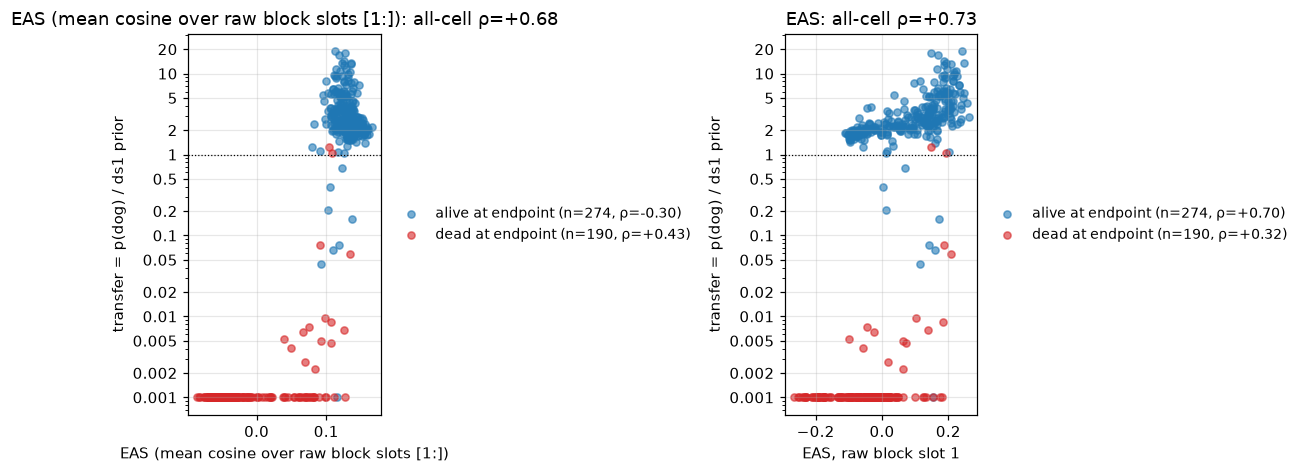

In [11]:
# Fig 7a. Endpoint scatter: EAS vs transfer, [1:]-mean (left) and the best slot (right). Point unit = one
# cell (endpoint ckpt); colour = alive/dead at the endpoint; x floored at S7_FLOOR for the log axis.
if need(s7):
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
    for ax, col, ttl in zip(axs, ['eas_mean', S7_BEST_COL], [EAS_LABEL, f'EAS, raw block slot {S7_BEST}']):
        for dead, colr, lab in [(False, 'tab:blue', 'alive at endpoint'), (True, 'tab:red', 'dead at endpoint')]:
            d = s7_end[s7_end.dead == dead]
            ax.scatter(d[col], np.maximum(d.ratio, S7_FLOOR), s=22, alpha=.6, color=colr,
                       label=f'{lab} (n={len(d)}, ρ={s7_rho(d[col], d.log_ratio):+.2f})')
        ax.axhline(1, color='k', lw=.8, ls=':')
        ax.set_yscale('log'); ax.set_xlabel(ttl); ax.set_ylabel('transfer = p(dog) / ds1 prior')
        ax.set_title(f'{ttl.split(",")[0]}: all-cell ρ={s7_rho(s7_end[col], s7_end.log_ratio):+.2f}')
        aplots.right_legend(ax)
    plt.tight_layout(); aplots.show()

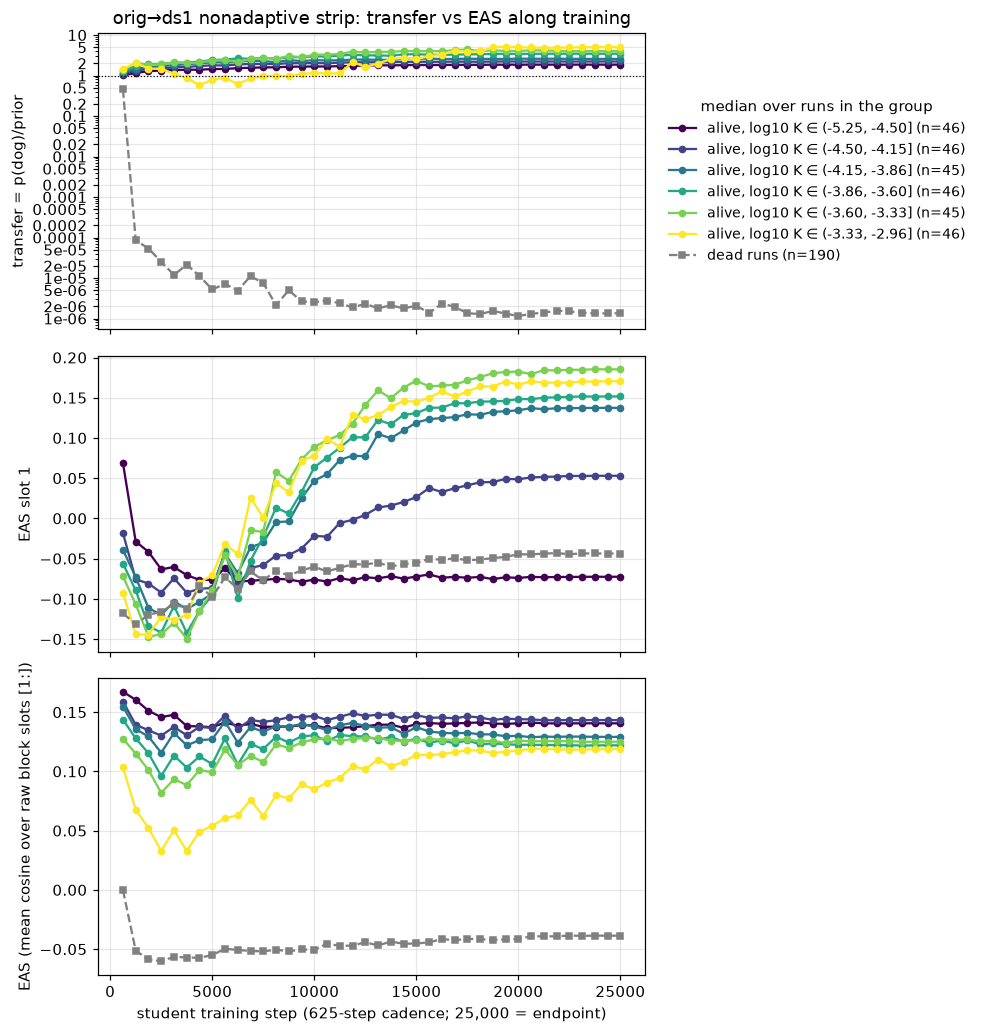

In [12]:
# Fig 7b. Trajectories on one step axis: median across alive runs within a dose (K) sextile of
# (top) transfer ratio, (middle) best-slot EAS, (bottom) [1:]-mean EAS. Dead runs are the grey band
# (median over dead runs). Same colour = same K sextile in all three panels.
if need(s7):
    alive = s7[~s7.run_dead].copy()
    kq = pd.qcut(np.log10(alive.drop_duplicates('run_path').set_index('run_path').K), 6)
    alive['Kq'] = alive.run_path.map(kq)
    dead = s7[s7.run_dead]
    cmap = plt.get_cmap('viridis')
    cats = list(kq.cat.categories)
    fig, axs = plt.subplots(3, 1, figsize=(9, 9.5), sharex=True)
    for ax, col, yl in zip(axs, ['ratio', S7_BEST_COL, 'eas_mean'],
                           ['transfer = p(dog)/prior', f'EAS slot {S7_BEST}', EAS_LABEL]):
        for i, c in enumerate(cats):
            g = alive[alive.Kq == c].groupby('step')[col].median()
            ax.plot(g.index, g.values, marker='o', ms=4, color=cmap(i / 5),
                    label=f'alive, log10 K ∈ ({c.left:.2f}, {c.right:.2f}] (n={alive[alive.Kq == c].run_path.nunique()})')
        g = dead.groupby('step')[col].median()
        ax.plot(g.index, g.values, marker='s', ms=4, color='0.5', ls='--', label=f'dead runs (n={dead.run_path.nunique()})')
        ax.set_ylabel(yl)
        if col == 'ratio':
            ax.set_yscale('log'); ax.axhline(1, color='k', lw=.8, ls=':')
    axs[-1].set_xlabel('student training step (625-step cadence; 25,000 = endpoint)')
    aplots.right_legend(axs[0], title='median over runs in the group')
    axs[0].set_title('orig→ds1 nonadaptive strip: transfer vs EAS along training')
    plt.tight_layout(); aplots.show()

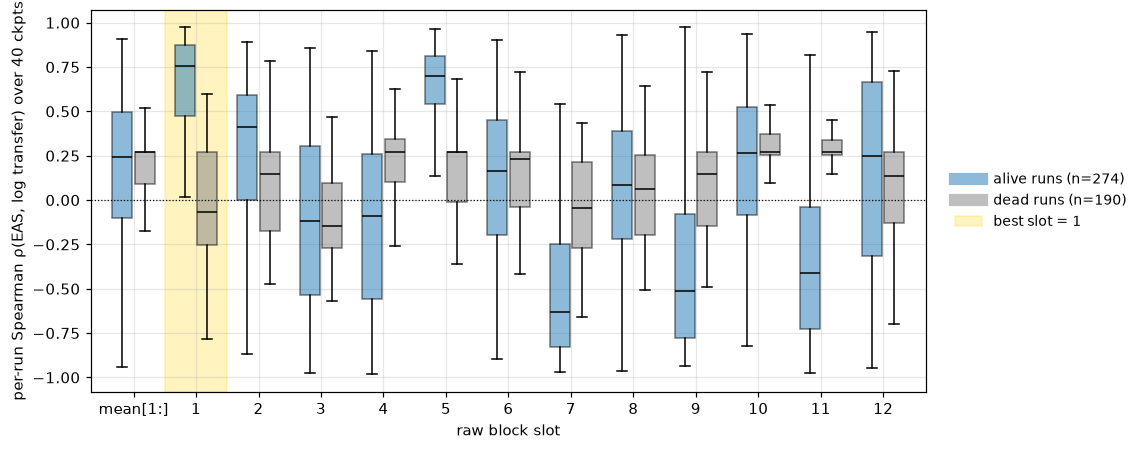

Endpoint medians by dose sextile (alive runs):


,n,transfer,kl,eas_mean,eas_l1,eas_l12
Kq,,,,,,
"(-5.251, -4.503]",46,1.857,0.091,0.141,-0.073,0.416
"(-4.503, -4.152]",46,2.221,0.161,0.143,0.053,0.414
"(-4.152, -3.857]",45,2.573,0.294,0.129,0.137,0.406
"(-3.857, -3.605]",46,3.453,0.454,0.122,0.152,0.401
"(-3.605, -3.33]",45,4.017,0.691,0.125,0.185,0.400
"(-3.33, -2.958]",46,5.016,1.906,0.119,0.170,0.397


In [13]:
# Fig 7c. Per-run trajectory rho, one box per slot: Spearman(EAS_slot, log transfer) over a run's 40 ckpts,
# alive runs (blue) vs dead runs (grey). Row unit inside a box = one run. Marks the best slot.
if need(s7):
    cols = ['eas_mean'] + [f'eas_l{l}' for l in S7_SLOTS]
    fig, ax = plt.subplots(figsize=(10.5, 4.2))
    pos = np.arange(len(cols))
    for frame, off, colr, lab in [(s7[~s7.run_dead], -.18, 'tab:blue', 'alive runs'),
                                  (s7[s7.run_dead], .18, '0.5', 'dead runs')]:
        data = [s7_within(frame, c).dropna().values for c in cols]
        bp = ax.boxplot(data, positions=pos + off, widths=.32, patch_artist=True, showfliers=False)
        for b in bp['boxes']: b.set(facecolor=colr, alpha=.5)
        for med in bp['medians']: med.set(color='k')
        ax.plot([], [], color=colr, lw=8, alpha=.5, label=f'{lab} (n={frame.run_path.nunique()})')
    ax.axhline(0, color='k', lw=.8, ls=':')
    ax.set_xticks(pos); ax.set_xticklabels(['mean[1:]'] + [str(l) for l in S7_SLOTS])
    ax.axvspan(S7_BEST - .5, S7_BEST + .5, color='gold', alpha=.25, label=f'best slot = {S7_BEST}')
    ax.set_xlabel('raw block slot'); ax.set_ylabel('per-run Spearman ρ(EAS, log transfer) over 40 ckpts')
    aplots.right_legend(ax)
    plt.tight_layout(); aplots.show()
    # Best-slot alive-run trajectory in dose bins (numbers behind Fig 7b, endpoint column)
    print('Endpoint medians by dose sextile (alive runs):')
    display(alive[alive.is_endpoint.astype(bool)].groupby('Kq', observed=True)
            .agg(n=('run_path', 'size'), transfer=('ratio', 'median'), kl=('kl', 'median'),
                 eas_mean=('eas_mean', 'median'), **{S7_BEST_COL: (S7_BEST_COL, 'median')}, eas_l12=('eas_l12', 'median')).round(3))

**Reading §7.** Over all cells the `[1:]`-mean EAS looks strongly predictive of transfer, but that is
the alive/dead partition: dead cells sit at EAS < 0 *and* transfer 0. Conditioned on alive cells the mean
EAS is flat-to-*negative* in transfer, because the deeper slots (6, 7, 11, 12) fall with dose (KL) while
transfer rises with dose up to the boundary. The single slot whose EAS rises with transfer both across
cells and along a trajectory is the **first raw block (slot 1)**: it is near zero at the lowest doses,
grows monotonically along training in step with the transfer trajectory, and is the only slot whose
per-run ρ is positive for essentially every alive run. Deep-slot EAS therefore reads as a *base-fidelity*
(integrity) signal — highest at tiny dose, decaying as the student moves off the base — whereas the
early-block EAS reads as the *trait-carrying* shift. Dead runs show no consistent EAS–transfer relation
at any slot (both readouts have collapsed).